# Population enrichments: what the four synthetic files show

The discovery calls with Adams State and the IU regional campuses described student groups and signals that the PDP Analysis-Ready Files don't carry. This notebook analyzes four synthetic files that fill those gaps, joined to the raw mock cohort and course files.

| File | Key | Where the idea comes from |
|---|---|---|
| `data/student_athlete.csv` | `is_student_athlete`, `athlete_sport` | Adams State: 45–50% of undergraduates are Division II athletes, who retain better. Retention dipped under a new football coach. |
| `data/registration_holds.csv` | `registration_hold` (by term) | IU advisors check students' remaining balance. Draft spec for proposal #19. |
| `data/lms_activity_band.csv` | `lms_activity_band` (by term) | IU uses Canvas activity scores for real-time outreach. |
| `data/instruction_site.csv` | `instruction_site` | Adams State runs on-campus, online and prison-education courses (5 Colorado Department of Corrections facilities). |

> **Every relationship below was planted by the generators** (see `README.md`, *Planted effects*). The notebook checks that each planted effect comes through after joining, and shows the analyses a squad would run on the real data. **None of it is a finding about real students or a real institution.**

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

HERE = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "student_athlete.py").is_file())
STARTER = HERE.parents[1] / "pdp-datathon-starter"
RAW, DATA = STARTER / "data" / "raw", HERE / "data"

sys.path.insert(0, str(STARTER / "notebooks"))
import plotting  # noqa: E402,F401  the starter notebooks' matplotlib style

# Reference palette: categorical slots 1-3, sequential blue, muted ink.
BLUE, ORANGE, AQUA, MUTED = "#2a78d6", "#eb6834", "#1baf7a", "#898781"
SEQ = {"low": "#86b6ef", "medium": "#2a78d6", "high": "#104281"}
MIN_N = 10  # suppress any group smaller than this (the shared success-measures rule)

read = lambda p: pd.read_csv(p, dtype=str, keep_default_na=False)
cohort_raw, course = read(RAW / "pdp_cohort_data.csv"), read(RAW / "pdp_course_data.csv")
athlete, holds = read(DATA / "student_athlete.csv"), read(DATA / "registration_holds.csv")
lms, site = read(DATA / "lms_activity_band.csv"), read(DATA / "instruction_site.csv")
for name, df in [("cohort", cohort_raw), ("course", course), ("student_athlete", athlete),
                 ("registration_holds", holds), ("lms_activity_band", lms), ("instruction_site", site)]:
    print(f"{name:20} {len(df):>7,} rows  {df.Student_GUID.nunique():>6,} students")

cohort                10,313 rows  10,311 students
course               100,951 rows  10,311 students
student_athlete       15,000 rows  10,311 students
registration_holds     9,329 rows   5,404 students
lms_activity_band     45,066 rows   9,855 students
instruction_site      10,311 rows  10,311 students


## Setup: one row per student, and one row per enrolled term

- **Students.** Two students appear in two cohorts. As in the normalized model, the later cohort's row wins, which leaves one row per student. `Retention` is coded `1`/`0`.
- **Enrolled terms.** These are the terms in which a student has a course-file row with a year and a term, the same definition the generators use. That includes terms where the student was enrolled **only at another institution** (no course record). Those terms get holds and LMS bands too, which a real SIS wouldn't produce, so they're flagged here and dropped where it matters.
- **Next-term enrollment** means having any row in the next fall or spring term. It's measured for fall and spring terms from 2021-22 through 2024-25, so that the next term is inside the data.

In [2]:
students = (cohort_raw.sort_values("Cohort").drop_duplicates("Student_GUID", keep="last")
            .set_index("Student_GUID"))
students["retained"] = students.Retention.eq("1")
students["ftft"] = students.Enrollment_Type.eq("First-Time") & students.Enrollment_Intensity_First_Term.eq("Full-Time")

TERMS = ["FALL", "WINTER", "SPRING", "SUMMER"]
dated = course[(course.Academic_Year != "") & (course.Academic_Term != "")]
terms = (dated.assign(here=dated.Course_Prefix.ne(""))
         .groupby(["Student_GUID", "Academic_Year", "Academic_Term"]).here.any().rename("enrolled_here").reset_index())

def next_main(year, term):
    if term == "FALL":
        return year, "SPRING"
    y = int(year[:4]) + 1
    return f"{y}-{str(y + 1)[-2:]}", "FALL"

keys = set(zip(terms.Student_GUID, terms.Academic_Year, terms.Academic_Term))
main = terms[terms.Academic_Term.isin(["FALL", "SPRING"]) & terms.Academic_Year.between("2021-22", "2024-25")].copy()
main["enrolled_next"] = [(g, *next_main(y, t)) in keys for g, y, t in zip(main.Student_GUID, main.Academic_Year, main.Academic_Term)]
print(f"{len(terms):,} enrolled student-terms; {(~terms.enrolled_here).sum():,} only at another institution")
print(f"{len(main):,} fall/spring student-terms with a measurable next term; "
      f"{main.enrolled_next.mean():.1%} enrolled the next term")

45,066 enrolled student-terms; 17,277 only at another institution
26,740 fall/spring student-terms with a measurable next term; 70.1% enrolled the next term


In [3]:
def rates(df, by, outcome):
    """n and rate of a true/false outcome by group, with groups under MIN_N suppressed."""
    t = df.groupby(by, observed=True)[outcome].agg(n="size", rate="mean")
    t["rate"] = t.rate.where(t.n >= MIN_N)
    return t

def pct(t):
    return t.style.format({"rate": lambda v: "suppressed" if pd.isna(v) else f"{v:.1%}", "n": "{:,}"})

## 1. Student athletes (Adams State)

**Planted:** about 45% of students are athletes, skewed toward first-time full-time students and those 20 and younger, with a small extra weight for retained students. Football and wrestling are male-only. In the 2023-24 cohort, non-retained students get three times the usual weight toward football, which simulates the dip under a new coach.

**Adams State's question:** "What do non-athletes who don't return for year 2 lack that athletes have?"

In [4]:
flag = athlete[athlete.Attribute_Key == "is_student_athlete"].set_index("Student_GUID").Attribute_Value.eq("true")
sport = athlete[athlete.Attribute_Key == "athlete_sport"].set_index("Student_GUID").Attribute_Value
students["athlete"] = flag.reindex(students.index).fillna(False).astype(bool)
students["sport"] = sport.reindex(students.index).fillna("not an athlete")
print(f"athletes: {students.athlete.mean():.1%} of {len(students):,} students")
pct(rates(students, "athlete", "retained"))

athletes: 45.5% of 10,311 students


,n,rate
athlete,,
False,"5,622",45.1%
True,"4,689",55.0%


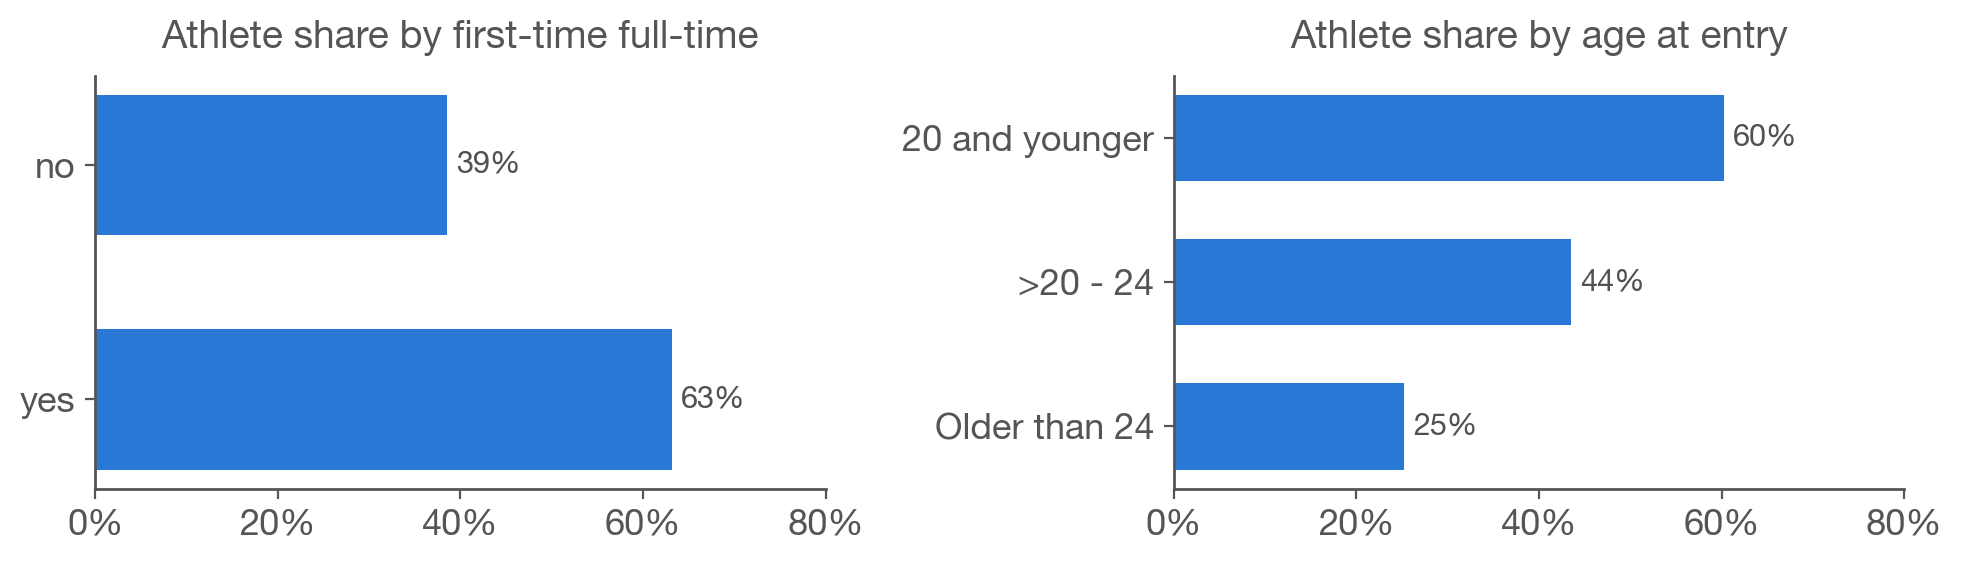

In [5]:
shares = pd.DataFrame({
    "first-time full-time": students.groupby("ftft").athlete.mean(),
}).rename(index={True: "yes", False: "no"})
by_age = students.groupby("Student_Age").athlete.mean().drop("Unknown", errors="ignore")
by_age = by_age.reindex(["20 and younger", ">20 - 24", "Older than 24"])

fig, axes = plt.subplots(1, 2, figsize=(10, 3), sharex=True)
for ax, s, title in [(axes[0], shares.iloc[:, 0], "First-time full-time"), (axes[1], by_age, "Age at entry")]:
    ax.barh(s.index, s.values, color=BLUE, height=0.6)
    for y, v in enumerate(s.values):
        ax.text(v + 0.01, y, f"{v:.0%}", va="center", color="#52514e", fontsize=11)
    ax.set_title(f"Athlete share by {title.lower()}"); ax.set_xlim(0, 0.8); ax.invert_yaxis()
    ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
plt.tight_layout()

The retention gap is bigger than the +0.2 retention weight alone would give. In the mock data, younger full-time students already retain better, and athletes skew toward them. A real analysis would compare within strata:

In [6]:
strat = students[students.Student_Age.ne("Unknown")].groupby(["ftft", "Student_Age", "athlete"]).retained.agg(["size", "mean"]).unstack("athlete")
strat.columns = [f"{m} ({'athlete' if a else 'non-athlete'})" for m, a in strat.columns]
strat["gap (pts)"] = (strat["mean (athlete)"] - strat["mean (non-athlete)"]) * 100
strat.style.format({c: "{:.1%}" for c in strat.columns if c.startswith("mean")} | {"gap (pts)": "{:+.1f}"})

### The coach-change dip: retention by cohort for football, other athletes and non-athletes

Football is about 170–260 students per cohort, so a few points either way is noise. Read the 2023-24 drop against the other athletes in the same cohort. **Every group falls in 2024-25.** That isn't planted: that cohort's year 2 (2025-26) is only partly in the course file, so its `Retention` is likely undercounted. Leave 2024-25 out of any trend.

group,football,not an athlete,other athletes
Cohort,,,
2021-22,187,1332,984
2022-23,194,1457,965
2023-24,256,1392,932
2024-25,172,1441,999


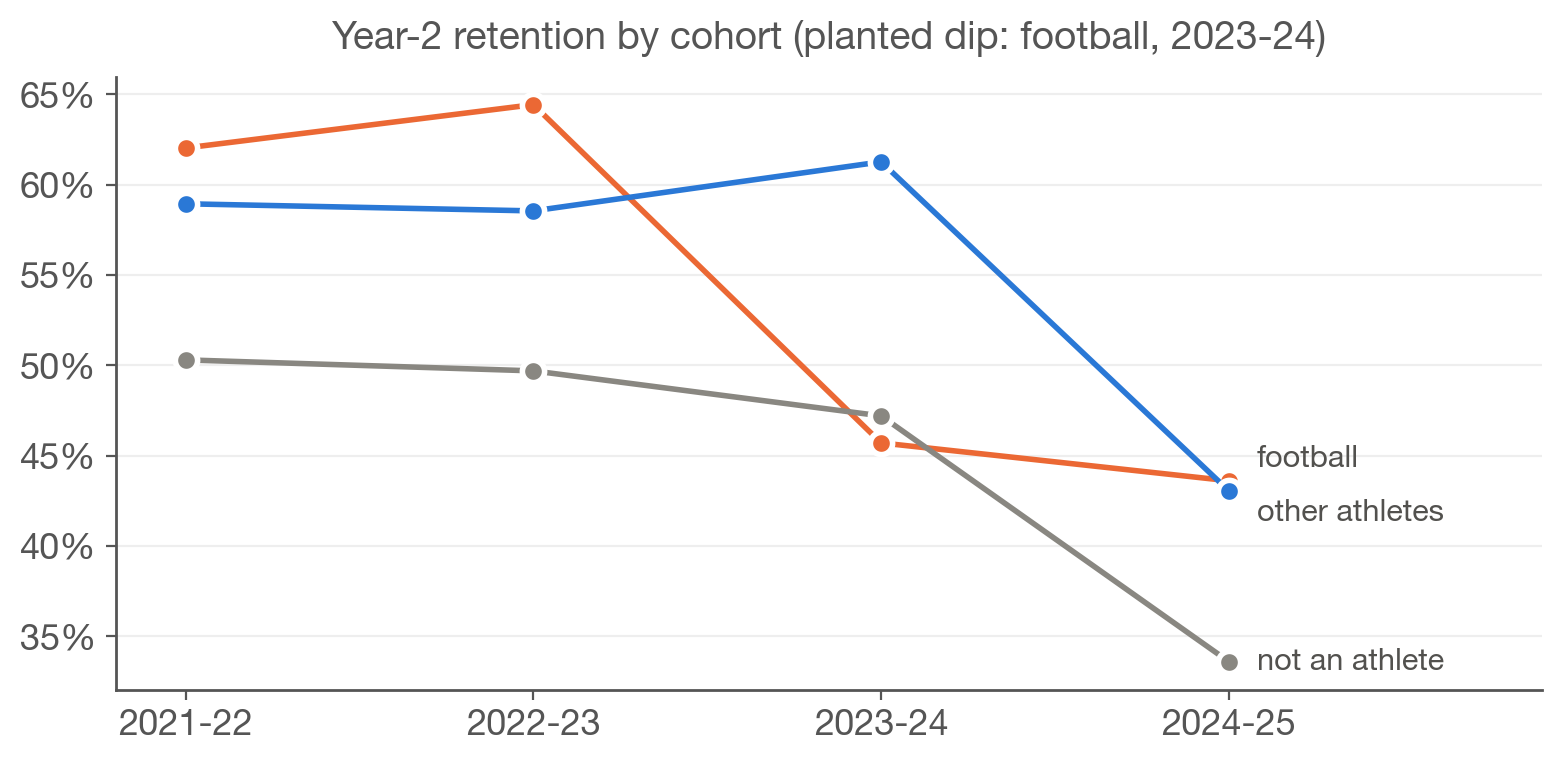

In [7]:
grp = students.assign(group=students.sport.where(students.sport.isin(["football", "not an athlete"]), "other athletes"))
by_cohort = grp.groupby(["Cohort", "group"]).retained.agg(["size", "mean"]).reset_index()
by_cohort.loc[by_cohort["size"] < MIN_N, "mean"] = None

fig, ax = plt.subplots(figsize=(8, 4))
for g, color, dy in [("football", ORANGE, 0.012), ("other athletes", BLUE, -0.012), ("not an athlete", MUTED, 0)]:
    d = by_cohort[by_cohort.group == g]
    ax.plot(d.Cohort, d["mean"], color=color, lw=2, marker="o", ms=8, markeredgecolor="white", markeredgewidth=2)
    ax.text(len(d) - 1 + 0.08, d["mean"].iloc[-1] + dy, g, color="#52514e", va="center", fontsize=11)
ax.set_title("Year-2 retention by cohort (planted dip: football, 2023-24)")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}"); ax.set_xlim(-0.2, 3.9); ax.grid(axis="y")
plt.tight_layout()
by_cohort.pivot(index="Cohort", columns="group", values="size")

### What non-retained non-athletes look like next to athletes

This is a profile comparison, not a causal claim. Apart from the athlete selection weights, nothing here was planted: the differences come from who the generator made athletes.

In [8]:
prof = students.assign(
    pell=students.Pell_Status_First_Year.eq("Y"),
    part_time=students.Enrollment_Intensity_First_Term.eq("Part-Time"),
    gateway_math_y1=students.CompletedGatewayMathYear1.eq("C"),
    credits_earned_y1=pd.to_numeric(students.Number_of_Credits_Earned_Yr_1, errors="coerce"),
    older_than_24=students.Student_Age.eq("Older than 24"),
)
groups = {
    "athletes, retained": prof[prof.athlete & prof.retained],
    "non-athletes, retained": prof[~prof.athlete & prof.retained],
    "non-athletes, not retained": prof[~prof.athlete & ~prof.retained],
}
pd.DataFrame({k: {"n": len(v), "Pell (Y)": v.pell.mean(), "part-time first term": v.part_time.mean(),
                  "older than 24": v.older_than_24.mean(), "completed gateway math Y1": v.gateway_math_y1.mean(),
                  "median credits earned Y1": v.credits_earned_y1.median()} for k, v in groups.items()}).T.style.format(
    {"n": "{:,.0f}", "median credits earned Y1": "{:.0f}"} | {c: "{:.0%}" for c in
     ["Pell (Y)", "part-time first term", "older than 24", "completed gateway math Y1"]})

,n,Pell (Y),part-time first term,older than 24,completed gateway math Y1,median credits earned Y1
"athletes, retained","2,579",41%,41%,15%,20%,16
"non-athletes, retained","2,535",36%,61%,43%,16%,14
"non-athletes, not retained","3,087",29%,71%,47%,5%,4


## 2. Registration holds (IU balance, proposal #19)

**Planted:** each hold type is drawn independently in each enrolled term. Financial holds are twice as likely for Pell students. Every hold type is 1.6 times as likely in a term the student doesn't follow with enrollment the next fall or spring.

The effect runs from "doesn't come back" to "has a hold". The generator can't plant causation, so a hold here predicts stopping out without causing it.

In [9]:
h = holds.merge(terms, on=["Student_GUID", "Academic_Year", "Academic_Term"], how="left")
print(f"{len(holds):,} holds on {holds.groupby(['Student_GUID','Academic_Year','Academic_Term']).ngroups:,} student-terms; "
      f"{(~h.enrolled_here.fillna(False).astype(bool)).sum():,} are in terms the student was only enrolled elsewhere")
print(holds.Hold_Type.value_counts().to_dict())
print(holds.groupby('Hold_Type').Hold_Status.value_counts().unstack(fill_value=0).to_string())

9,329 holds on 8,675 student-terms; 3,176 are in terms the student was only enrolled elsewhere
{'financial': 4175, 'advising': 2581, 'sap': 1540, 'immunization': 783, 'disciplinary': 250}
Hold_Status   active  resolved  waived
Hold_Type                             
advising         364      2013     204
disciplinary      31       200      19
financial        494      3347     334
immunization     118       607      58
sap              185      1223     132


In [10]:
term_holds = holds.pivot_table(index=["Student_GUID", "Academic_Year", "Academic_Term"], columns="Hold_Type",
                               aggfunc="size", fill_value=0).gt(0)
here = terms[terms.enrolled_here].set_index(["Student_GUID", "Academic_Year", "Academic_Term"])
here = here.join(term_holds.reindex(here.index, fill_value=False))
here["pell"] = students.Pell_Status_First_Year.reindex(here.index.get_level_values(0)).eq("Y").values
here["any_hold"] = here[term_holds.columns].any(axis=1)

fin = here.groupby("pell").financial.agg(n="size", rate="mean").rename(index={True: "Pell Y", False: "Pell N or U"})
print("Share of enrolled terms (at this institution) with a financial hold")
pct(fin)

Share of enrolled terms (at this institution) with a financial hold


,n,rate
pell,,
Pell N or U,"16,637",7.2%
Pell Y,"11,152",14.4%


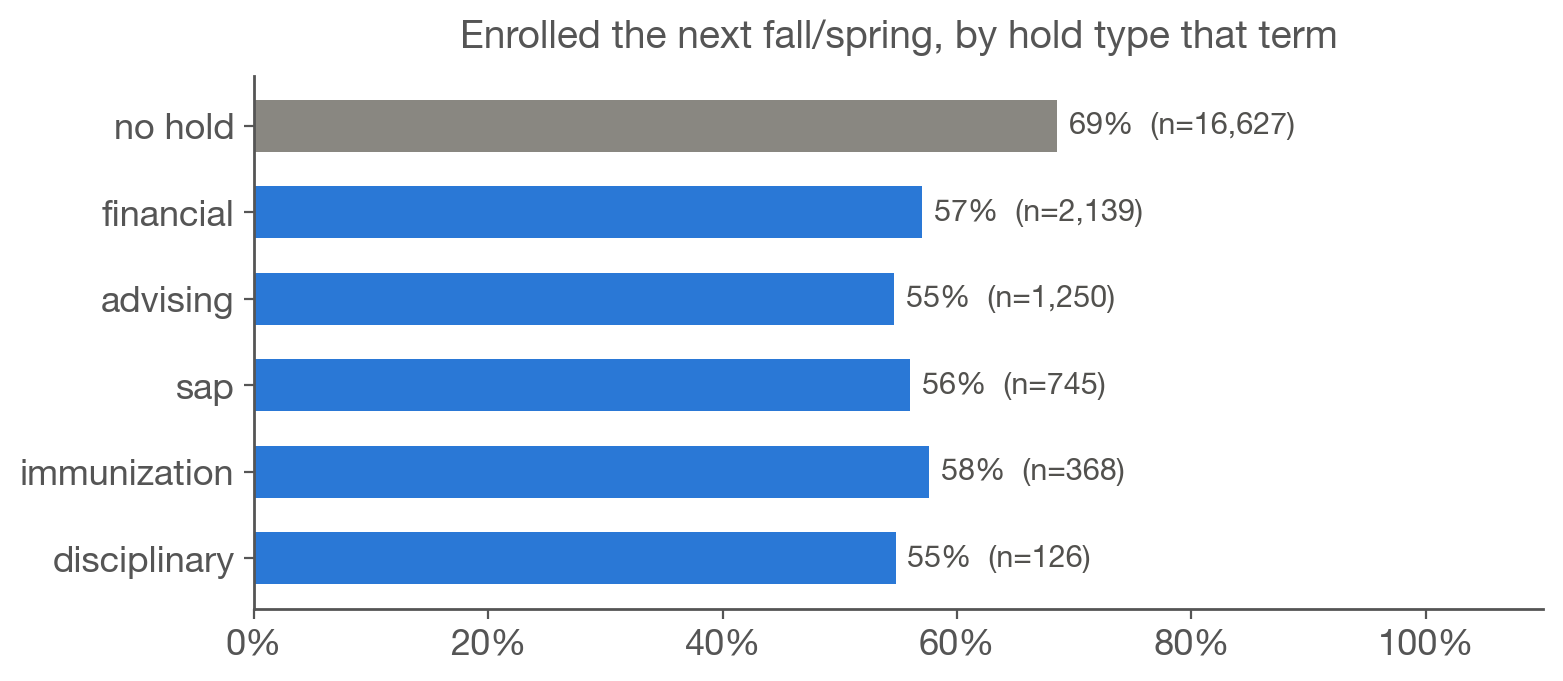

In [11]:
m = main[main.enrolled_here].set_index(["Student_GUID", "Academic_Year", "Academic_Term"])
m = m.join(term_holds.reindex(m.index, fill_value=False))
m["any_hold"] = m[term_holds.columns].any(axis=1)
rows = {"no hold": m[~m.any_hold].enrolled_next}
rows |= {t: m[m[t]].enrolled_next for t in ["financial", "advising", "sap", "immunization", "disciplinary"]}
nt = pd.DataFrame({k: {"n": len(v), "rate": v.mean() if len(v) >= MIN_N else None} for k, v in rows.items()}).T

fig, ax = plt.subplots(figsize=(8, 3.6))
colors = [MUTED] + [BLUE] * (len(nt) - 1)
ax.barh(nt.index, nt.rate.astype(float), color=colors, height=0.6)
for y, (v, n) in enumerate(zip(nt.rate, nt.n)):
    ax.text(float(v) + 0.01, y, f"{float(v):.0%}  (n={int(n):,})", va="center", color="#52514e", fontsize=11)
ax.set_xlim(0, 1.1); ax.invert_yaxis(); ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_title("Enrolled the next fall/spring, by hold type that term")
plt.tight_layout()

## 3. LMS activity band (IU Canvas activity)

**Planted:** `score = gauss(0,1) − 1.5 × (DFW share − 0.25)`. A score below −0.6 is **low**, above 0.6 **high**. The DFW share is the share of the student's gradeable courses that term graded below 2.0, F, W or UW.

The band is generated from the same term's grades, so it's a *concurrent* signal, not a leading one. Against the real Canvas data, the test that matters is whether week-4 activity predicts end-of-term DFW.

In [12]:
GRADE_NUM = pd.to_numeric(course.Grade, errors="coerce")
gradeable = course[GRADE_NUM.notna() | course.Grade.isin(["P", "F", "W", "UW"])].copy()
gradeable["dfw"] = GRADE_NUM.reindex(gradeable.index).lt(2.0) | gradeable.Grade.isin(["F", "W", "UW"])
dfw = gradeable.groupby(["Student_GUID", "Academic_Year", "Academic_Term"]).dfw.mean().rename("dfw_share")
lb = lms.set_index(["Student_GUID", "Academic_Year", "Academic_Term"]).join(dfw)
lb["band"] = pd.Categorical(lb.LMS_Activity_Band, ["low", "medium", "high"], ordered=True)
summary = lb.groupby("band", observed=True).agg(student_terms=("dfw_share", "size"), dfw_known=("dfw_share", "count"),
                                                 mean_dfw_share=("dfw_share", "mean"))
summary.style.format({"student_terms": "{:,}", "dfw_known": "{:,}", "mean_dfw_share": "{:.2f}"})

,student_terms,dfw_known,mean_dfw_share
band,,,
low,"12,813","7,949",0.50
medium,"18,979","10,871",0.19
high,"13,274","8,415",0.07


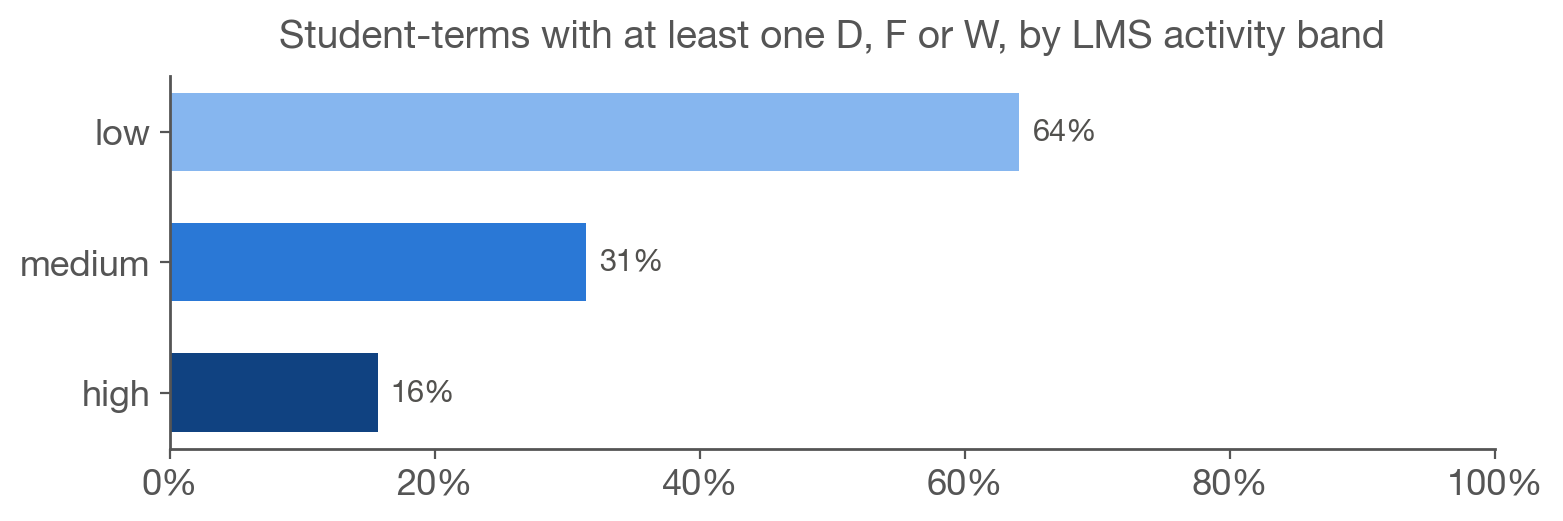

In [13]:
any_dfw = lb.dropna(subset=["dfw_share"]).assign(any_dfw=lambda d: d.dfw_share.gt(0)).groupby("band", observed=True).any_dfw.mean()
fig, ax = plt.subplots(figsize=(8, 2.8))
ax.barh(any_dfw.index.astype(str), any_dfw.values, color=[SEQ[b] for b in any_dfw.index], height=0.6)
for y, v in enumerate(any_dfw.values):
    ax.text(v + 0.01, y, f"{v:.0%}", va="center", color="#52514e", fontsize=11)
ax.invert_yaxis(); ax.set_xlim(0, 1); ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_title("Student-terms with at least one D, F or W, by LMS activity band")
plt.tight_layout()

### An outreach list IU could use

IU's advisors work from lists of about 150 students and want them under 50. One way to cut: students with **low** activity **and** an open hold in the same term, counting only terms enrolled here.

In [14]:
low = lb[lb.LMS_Activity_Band == "low"].index
outreach = here.loc[here.index.intersection(low)]
outreach = outreach[outreach.any_hold]
sizes = pd.DataFrame({
    "low activity": pd.Series(1, index=here.index.intersection(low)).groupby(level=[1, 2]).size(),
    "low activity + any hold": outreach.groupby(level=[1, 2]).size(),
}).fillna(0).astype(int)
sizes = sizes.loc[[i for i in sizes.index if i[0] >= "2021-22" and i[1] in ("FALL", "SPRING")]]
sizes

low activity  low activity + any hold
Academic_Year Academic_Term                                       
2021-22       FALL                    520                      127
              SPRING                  540                       97
2022-23       FALL                    847                      179
              SPRING                  818                      181
2023-24       FALL                    864                      181
              SPRING                  731                      160
2024-25       FALL                   1027                      236
              SPRING                  890                      189
2025-26       FALL                    470                      122
              SPRING                  116                       16

Combining the two signals cuts each term's list by about four-fifths. It still leaves 100–240 students a term, against IU's target of under 50. Low activity is about 28% of student-terms by construction, so a third filter is needed: for example, a financial hold only, or students who also have a D, F or W at midterm. On the real data, the question is which cut keeps the students who actually don't return.

## 4. Instruction site (Adams State)

**Planted:** `cdoc_facility` is assigned by age, at about 50 students and mostly older than 24. That small size is intentional: it exercises the rule that groups under 10 are suppressed. `online` is assigned by the share of a student's courses with `Delivery_Method = O`.

In [15]:
students["site"] = site.set_index("Student_GUID").Instruction_Site.reindex(students.index)
online_share = course[course.Delivery_Method != ""].assign(o=lambda d: d.Delivery_Method.eq("O")).groupby("Student_GUID").o.mean()
students["online_course_share"] = online_share.reindex(students.index)
t = students.groupby("site").agg(n=("site", "size"), older_than_24=("Student_Age", lambda s: s.eq("Older than 24").mean()),
                                 online_course_share=("online_course_share", "mean"), retained=("retained", "mean"))
t.style.format({"n": "{:,}", "older_than_24": "{:.0%}", "online_course_share": "{:.2f}", "retained": "{:.1%}"})

,n,older_than_24,online_course_share,retained
site,,,,
cdoc_facility,46,70%,0.52,41.3%
on_campus,"7,224",32%,0.30,52.7%
online,"3,041",35%,0.81,42.3%


Retention by site and race, with groups under 10 suppressed. Nearly every `cdoc_facility` cell is suppressed, so in a real dashboard that row would show only its total.

In [16]:
x = rates(students, ["site", "Race"], "retained")["rate"].unstack("site")
print(f"suppressed cells: {x.isna().sum().to_dict()}")
x.style.format(lambda v: "—" if pd.isna(v) else f"{v:.0%}")

suppressed cells: {'cdoc_facility': 6, 'on_campus': 0, 'online': 1}


site,cdoc_facility,on_campus,online
Race,,,
American Indian or Alaska,—,42%,38%
Asian,—,59%,45%
Black or African American,45%,46%,37%
Hispanic,45%,52%,45%
Native Hawaiian or Other,—,29%,—
Nonresident alien,—,63%,50%
Two or More Races,—,50%,44%
Unknown,—,47%,42%
White,36%,56%,42%


## Caveats before loading these into the model

1. **Enrolled terms include terms at other institutions.** These are 17,277 of the 45,066 enrolled student-terms (38%), and 3,176 of the 9,329 holds. Holds and LMS bands are written for those terms too. A real SIS or Canvas can't produce them. The fix is to change the generators' enrolled-term rule to require a course record (`Course_Prefix` non-blank).
2. **All effects are planted and one-directional.** Holds are generated from later enrollment, and LMS bands from the same term's grades. Neither can be used as evidence that holds or low activity *cause* stop-outs.
3. **`First_Gen`'s Y/N may be reversed** relative to the dictionary (see `pdp-datathon-starter/notebooks/deep_dive.ipynb`). None of these generators use it, but don't profile athletes or holds by first-gen without reading that first.
4. **To load into the normalized model**, copy `config/*_mapping.yaml` into `normalized-data-model/config/`, merge `config/destination_schema_rules.yaml` into `destination_schema.yaml`, and load with `pipeline_populations.yaml`. Until then, `demo/.data/pdp.sqlite` doesn't have these rows.